# Day 4 hands-on: learning uncertainties

A network output without an uncertainty is a measurement without an error bar. In this session we train a regression network that predicts, for every input $x$, both a value $f_\theta(x)$ and its uncertainty $\sigma_\theta(x)$, using the heteroskedastic loss from the lecture,
$$\mathcal{L} = \left\langle \frac{|y - f_\theta(x)|^2}{2\sigma_\theta(x)^2} + \log \sigma_\theta(x) \right\rangle \; .$$
We inject noise of known size into the training data and check whether the network finds it.

**Colab:** everything runs on the CPU, each training takes a few seconds. Run the cells from top to bottom with `Shift+Enter`.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

## 1) A regression task with injected noise

The target is $f(x) = \sin(2\pi x)$ for $x \in [0,1]$. We add Gaussian noise to every training target, $y = f(x) + \sigma(x)\,\epsilon$ with $\epsilon \sim \mathcal{N}(0,1)$, where the width $\sigma(x)$ depends on $x$: the noise is **heteroskedastic**. The network never sees $\sigma(x)$, only the noisy pairs $(x, y)$.

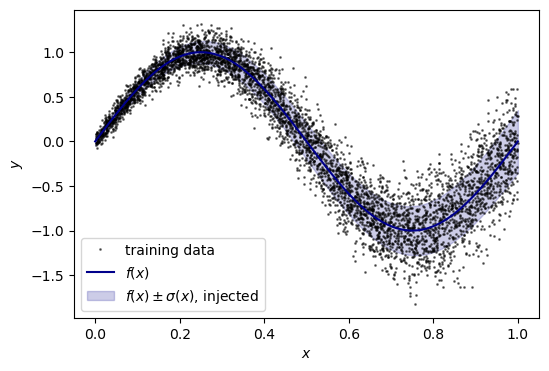

In [2]:
def f_true(x):
    return torch.sin(2 * math.pi * x)


def sigma_linear(x):
    return 0.05 + 0.3 * x                       # the injected noise grows with x


def make_data(n, sigma_fn, x_min=0.0, x_max=1.0):
    x = x_min + (x_max - x_min) * torch.rand(n, 1)
    y = f_true(x) + sigma_fn(x) * torch.randn_like(x)
    return x, y


x_train, y_train = make_data(5000, sigma_linear)
x_plot = torch.linspace(0, 1, 200)[:, None]

plt.figure(figsize=(6, 4))
plt.plot(x_train, y_train, ".", color="black", ms=2, alpha=0.5, label="training data")
plt.plot(x_plot, f_true(x_plot), color="darkblue", label="$f(x)$")
plt.fill_between(x_plot[:, 0], (f_true(x_plot) - sigma_linear(x_plot))[:, 0],
                 (f_true(x_plot) + sigma_linear(x_plot))[:, 0], color="darkblue", alpha=0.2,
                 label="$f(x) \\pm \\sigma(x)$, injected")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()

### The usual regression
First the regression from Day 1: a network with one output, trained with the MSE. Nothing to do here, just run it. It learns the mean well, but it has no way to tell us that the data at $x \approx 1$ is much noisier than at $x \approx 0$.

final loss 0.053


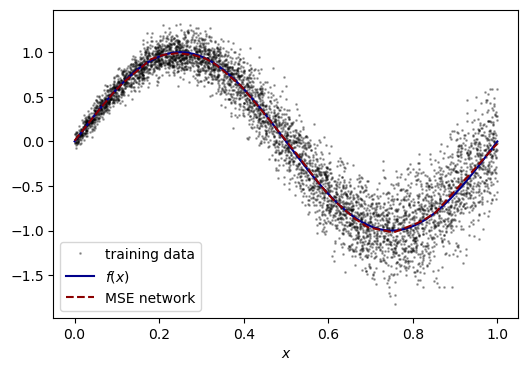

In [3]:
class Regressor(nn.Module):
    def __init__(self, n_outputs=1, n_hidden=64):
        super().__init__()
        self.layer1 = nn.Linear(1, n_hidden)
        self.layer2 = nn.Linear(n_hidden, n_hidden)
        self.layer3 = nn.Linear(n_hidden, n_hidden)
        self.layer4 = nn.Linear(n_hidden, n_outputs)

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = torch.relu(self.layer2(x))
        x = torch.relu(self.layer3(x))
        return self.layer4(x)


def train(model, x, y, loss_function, n_epochs=200, lr=1e-3):
    loader = DataLoader(TensorDataset(x, y), batch_size=256, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, n_epochs)   # smaller steps towards the end
    for epoch in range(n_epochs):
        for x_batch, y_batch in loader:
            loss = loss_function(model(x_batch), y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        scheduler.step()
    print(f"final loss {loss.item():.3f}")


def mse_loss(output, y):
    return ((output - y)**2).mean()


mse_model = Regressor(n_outputs=1)
train(mse_model, x_train, y_train, mse_loss)

with torch.no_grad():
    f_mse = mse_model(x_plot)
plt.figure(figsize=(6, 4))
plt.plot(x_train, y_train, ".", color="black", ms=2, alpha=0.3, label="training data")
plt.plot(x_plot, f_true(x_plot), color="darkblue", label="$f(x)$")
plt.plot(x_plot, f_mse, color="darkred", ls="--", label="MSE network")
plt.xlabel("$x$")
plt.legend()
plt.show()

## 2) Task 1: the heteroskedastic loss

We give the network a second output. The first output is the prediction $f_\theta(x)$, the second is $\log \sigma_\theta(x)$: predicting the logarithm guarantees $\sigma_\theta = e^{\log \sigma_\theta} > 0$ for any network output.

**Task:** implement the heteroskedastic loss, the negative logarithm of a Gaussian likelihood with learned mean and width. Then train and compare the learned $\sigma_\theta(x)$ with the injected $\sigma(x)$.

In [4]:
def heteroskedastic_loss(output, y):
    f_pred, log_sigma = output[:, :1], output[:, 1:]
    ########################################
    ### Implement the loss here ###
    loss = (y - f_pred)**2 / (2 * torch.exp(2 * log_sigma)) + log_sigma
    ########################################
    return loss.mean()

final loss -1.316


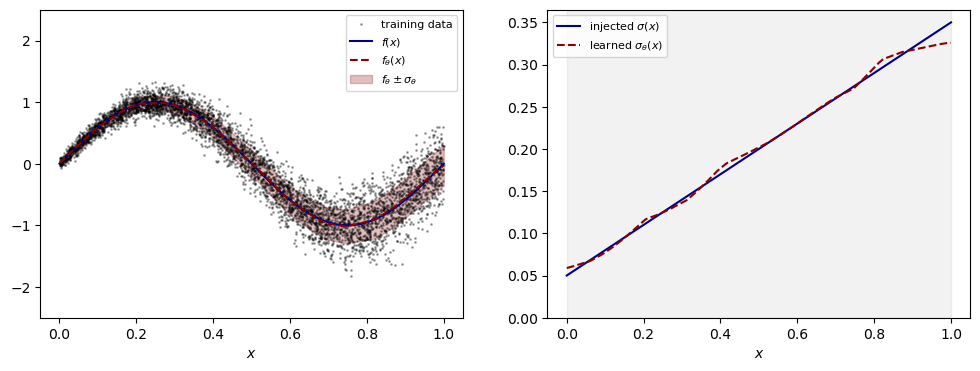

In [5]:
def predict(model, x):
    with torch.no_grad():
        output = model(x)
    return output[:, :1], output[:, 1:].exp()          # f_theta(x), sigma_theta(x)


def plot_prediction(model, sigma_fn, x_train, y_train, x_range=(0, 1)):
    x = torch.linspace(*x_range, 300)[:, None]
    f_pred, sigma_pred = predict(model, x)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ax = axes[0]
    ax.plot(x_train, y_train, ".", color="black", ms=2, alpha=0.3, label="training data")
    ax.plot(x, f_true(x), color="darkblue", label="$f(x)$")
    ax.plot(x, f_pred, color="darkred", ls="--", label="$f_\\theta(x)$")
    ax.fill_between(x[:, 0], (f_pred - sigma_pred)[:, 0], (f_pred + sigma_pred)[:, 0],
                    color="darkred", alpha=0.25, label="$f_\\theta \\pm \\sigma_\\theta$")
    ax.set_xlabel("$x$")
    ax.set_ylim(-2.5, 2.5)
    ax.legend(fontsize=8)
    ax = axes[1]
    inside = (x[:, 0] >= 0) & (x[:, 0] <= 1)                  # the noise is only injected where we have data
    ax.plot(x[inside], (sigma_fn(x) * torch.ones_like(x))[inside], color="darkblue", label="injected $\\sigma(x)$")
    ax.axvspan(0, 1, color="grey", alpha=0.1)
    ax.plot(x, sigma_pred, color="darkred", ls="--", label="learned $\\sigma_\\theta(x)$")
    ax.set_xlabel("$x$")
    ax.set_ylim(0, None)
    ax.legend(fontsize=8)
    plt.show()


het_model = Regressor(n_outputs=2)
train(het_model, x_train, y_train, heteroskedastic_loss)
plot_prediction(het_model, sigma_linear, x_train, y_train)

**Solution notes:** the learned width follows the injected $\sigma(x)$ within a few percent, although the network never saw it: it is only known implicitly, through the spread of the training targets around their mean. The two terms of the loss pull in opposite directions. The first term alone would make $\sigma_\theta$ large, the $\log \sigma_\theta$ term makes it small, and the balance is reached at $\sigma_\theta^2(x) = \langle |y - f_\theta(x)|^2 \rangle$, the local variance of the residuals.

## 3) Task 2: does the uncertainty follow the noise?

**Task:** inject a different noise pattern and check that the learned $\sigma_\theta(x)$ follows it. Some ideas are listed in the cell, but invent your own. What happens where the noise is zero?

final loss -2.125


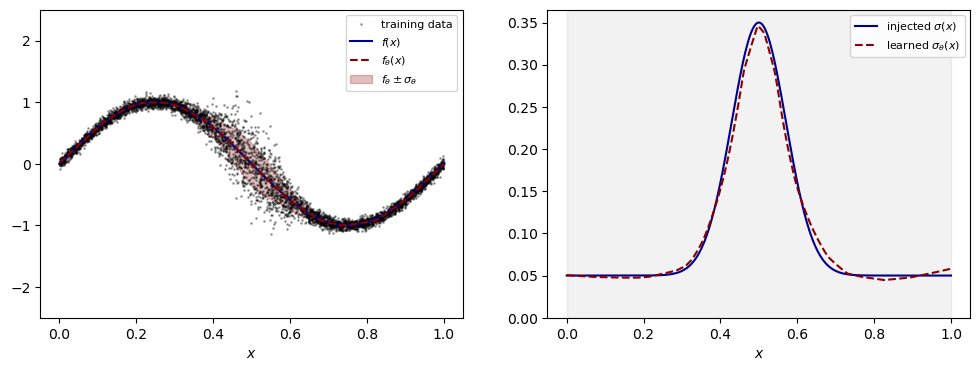

In [6]:
def sigma_new(x):
    ########################################
    ### Define the injected noise here ###
    return 0.05 + 0.3 * torch.exp(-((x - 0.5) / 0.1)**2)     # a bump in the middle
    # return 0.1 * torch.ones_like(x)                        # constant noise
    # return 0.05 + 0.25 * (x > 0.5).float()                 # a step
    # return 0.3 * torch.abs(torch.sin(4 * math.pi * x))     # oscillating, with zeros
    ########################################


x_new, y_new = make_data(5000, sigma_new)
het_new = Regressor(n_outputs=2)
train(het_new, x_new, y_new, heteroskedastic_loss)
plot_prediction(het_new, sigma_new, x_new, y_new)

**Solution notes:** smooth patterns like the bump are reproduced well. At a step the learned width is smeared out over a small range, because the network is a smooth function and needs data on both sides to locate the step. Where the injected noise vanishes, the learned width does not reach zero: it saturates at the level where the network cannot describe $f(x)$ any better. The heteroskedastic uncertainty captures the noise *and* the limited expressivity of the network, as discussed in the lecture.

## 4) Task 3: are the uncertainties correct? Pulls

In physics we test error bars with **pulls**: for independent test points,
$$\text{pull} = \frac{y - f_\theta(x)}{\sigma_\theta(x)}$$
should follow a standard Gaussian, mean 0 and width 1, if the prediction is unbiased and the uncertainties are right. A width above 1 means underestimated uncertainties, below 1 overestimated ones.

**Task:** compute the pulls of the heteroskedastic network from Task 1 on a fresh test set. For comparison, the cell also computes the pulls of the MSE network with a single constant uncertainty, the root mean square of its residuals. Compare the two distributions, and look at the pulls as a function of $x$.

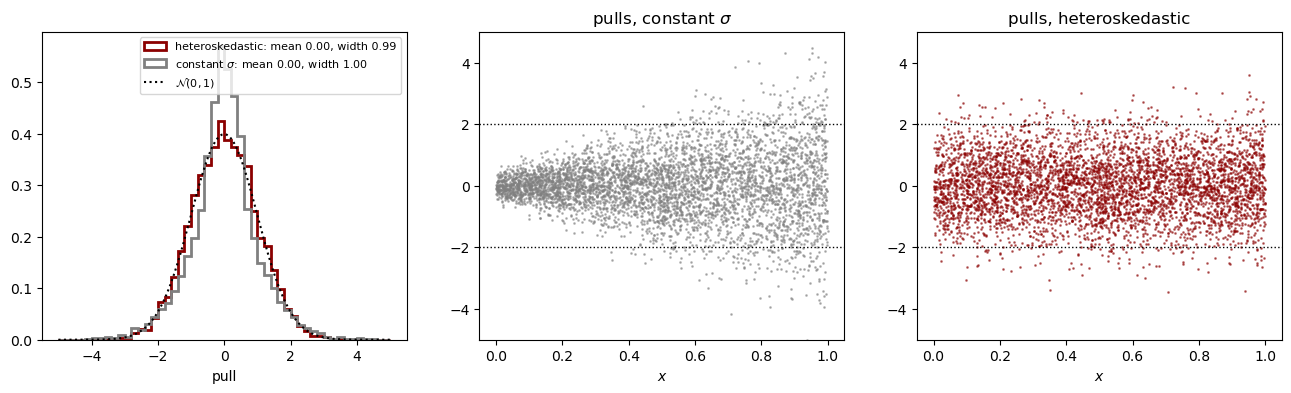

In [7]:
x_test, y_test = make_data(5000, sigma_linear)
f_het, sigma_het = predict(het_model, x_test)

########################################
### Compute the pulls here ###
pulls_het = ((y_test - f_het) / sigma_het)[:, 0]
########################################

with torch.no_grad():
    f_mse_test = mse_model(x_test)
sigma_const = ((y_test - f_mse_test)**2).mean().sqrt()          # one uncertainty for all x
pulls_const = ((y_test - f_mse_test) / sigma_const)[:, 0]

bins = np.linspace(-5, 5, 51)
z = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ax = axes[0]
ax.hist(pulls_het, bins, density=True, histtype="step", color="darkred", lw=2,
        label=f"heteroskedastic: mean {pulls_het.mean():.2f}, width {pulls_het.std():.2f}")
ax.hist(pulls_const, bins, density=True, histtype="step", color="grey", lw=2,
        label=f"constant $\\sigma$: mean {pulls_const.mean():.2f}, width {pulls_const.std():.2f}")
ax.plot(z, np.exp(-z**2 / 2) / np.sqrt(2 * np.pi), color="black", ls=":", label="$\\mathcal{N}(0,1)$")
ax.set_xlabel("pull")
ax.legend(fontsize=8)
for ax, pulls, name, color in [(axes[1], pulls_const, "constant $\\sigma$", "grey"),
                               (axes[2], pulls_het, "heteroskedastic", "darkred")]:
    ax.plot(x_test, pulls, ".", color=color, ms=2, alpha=0.5)
    ax.axhline(2, color="black", ls=":", lw=1)
    ax.axhline(-2, color="black", ls=":", lw=1)
    ax.set_title(f"pulls, {name}")
    ax.set_xlabel("$x$")
    ax.set_ylim(-5, 5)
plt.show()

**Solution notes:** the heteroskedastic pulls follow the standard Gaussian, with the same width everywhere in $x$. The constant uncertainty also has width one *on average*, by construction, but the pulls fan out: it overestimates the uncertainty at small $x$ and underestimates it at large $x$, and the combined distribution is not Gaussian. A pull distribution of width one is necessary, but only pulls that look right everywhere in phase space tell us that the uncertainties are right.

## 5) Task 4: a quantile calibration curve

The pulls test the width of the uncertainties. A **calibration curve** tests the predicted distribution as a whole. The network predicts a Gaussian $\mathcal{N}(f_\theta(x), \sigma_\theta(x)^2)$ for every $x$, so it also predicts every quantile: below
$$y_q(x) = f_\theta(x) + \sigma_\theta(x)\,\Phi^{-1}(q)$$
we expect a fraction $q$ of the targets, where $\Phi^{-1}$ is the inverse of the cumulative distribution of the standard Gaussian, `torch.special.ndtri(q)` in PyTorch. For calibrated uncertainties the observed fraction of test points with $y \le y_q(x)$ equals $q$ for every $q$, and the curve of observed vs predicted fraction lies on the diagonal. The coverage of a central interval from the lecture follows from two quantiles: the 68% interval runs from $q = 0.16$ to $q = 0.84$.

**Task:** implement the observed fraction for a list of quantile levels $q$. The cell then plots the calibration curves of the heteroskedastic network and of the constant uncertainty, for all test points and in two slices of $x$.

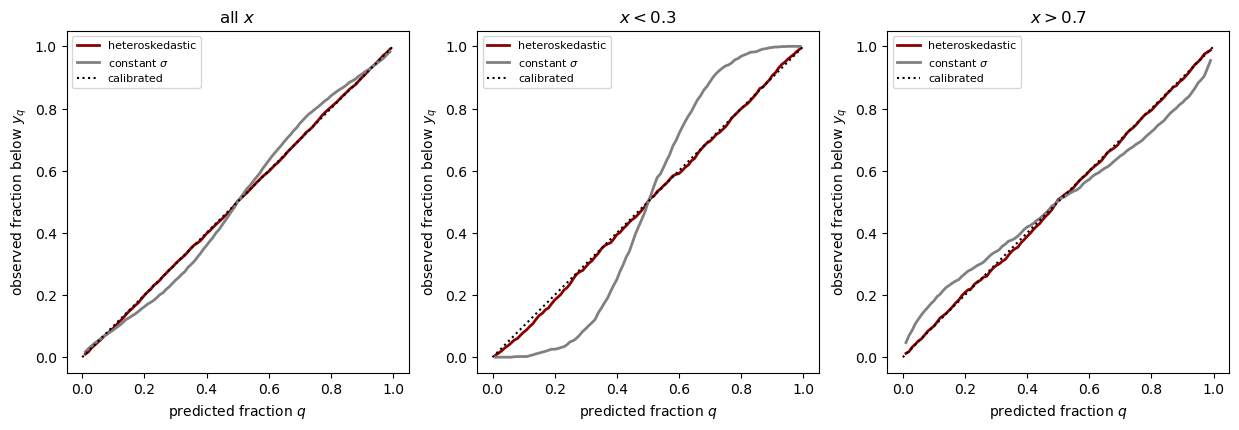

In [8]:
def observed_fraction(y, f_pred, sigma_pred, q):
    """Fraction of the targets y below the predicted q-quantiles, for each level in q."""
    ########################################
    ### Implement the observed fraction here ###
    y_q = f_pred + sigma_pred * torch.special.ndtri(q)[None, :]     # predicted quantiles, shape (n_points, n_q)
    fraction = (y <= y_q).float().mean(0)                            # shape (n_q,)
    ########################################
    return fraction


q = torch.linspace(0.01, 0.99, 99)
sigma_const_test = sigma_const * torch.ones_like(f_mse_test)
slices = [("all $x$", x_test[:, 0] >= 0),
          ("$x < 0.3$", x_test[:, 0] < 0.3),
          ("$x > 0.7$", x_test[:, 0] > 0.7)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, mask) in zip(axes, slices):
    for f_pred, sigma_pred, label, color in [(f_het, sigma_het, "heteroskedastic", "darkred"),
                                             (f_mse_test, sigma_const_test, "constant $\\sigma$", "grey")]:
        fraction = observed_fraction(y_test[mask], f_pred[mask], sigma_pred[mask], q)
        ax.plot(q, fraction, color=color, lw=2, label=label)
    ax.plot([0, 1], [0, 1], color="black", ls=":", label="calibrated")
    ax.set_title(name)
    ax.set_xlabel("predicted fraction $q$")
    ax.set_ylabel("observed fraction below $y_q$")
    ax.set_aspect("equal")
    ax.legend(fontsize=8, loc="upper left")
plt.show()

**Solution notes:** the heteroskedastic network lies on the diagonal in all three panels: its Gaussian quantiles are right everywhere in $x$. The constant uncertainty is too large for $x < 0.3$, where its curve is steeper than the diagonal in the middle: too few targets fall into the tails, the uncertainty is underconfident. For $x > 0.7$ it is too small, the curve is flatter, too many targets fall into the tails, and the uncertainty is overconfident. Over all $x$ the curve is still steeper than the diagonal, although the pulls have width one by construction: a mixture of too wide and too narrow intervals gives a pull distribution which is more peaked than a Gaussian, with heavier tails, the *same width, different tails* of the lecture. The deviation over all $x$ is much smaller than in the slices, so a curve that looks almost right on average can hide uncertainties that are wrong almost everywhere. A curve shifted up or down as a whole would instead indicate a biased prediction $f_\theta$, which the coverage of a symmetric interval cannot see. The calibration curve is the cumulative distribution of $\Phi(\text{pull})$, so it carries the same information as the pull histogram, but it reads off directly as coverage. For non-Gaussian noise the Gaussian quantiles would be wrong even with the correct width; then the network has to learn the quantiles, or the full distribution, itself.

## 6) Task 5: what the network does not know

Our training data covers $x \in [0,1]$. **Task:** plot the prediction of the heteroskedastic network for $x \in [-0.3, 1.3]$. Does the learned uncertainty warn us when we leave the training data?

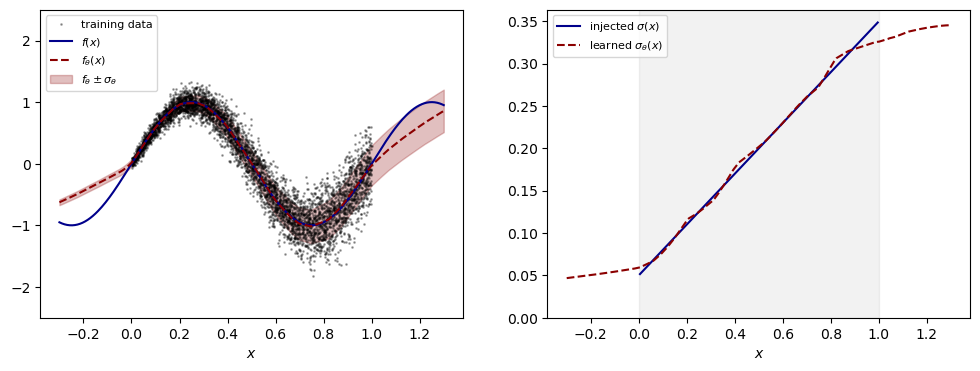

In [9]:
########################################
### Choose the x-range here ###
x_range = (-0.3, 1.3)
########################################
plot_prediction(het_model, sigma_linear, x_train, y_train, x_range=x_range)

**Solution notes:** outside the training data the prediction $f_\theta$ departs from $\sin(2\pi x)$, but $\sigma_\theta$ just continues its trend from inside, and at $x < 0$ it even becomes smaller. The heteroskedastic loss learns the noise *in the data*, the aleatoric or systematic uncertainty from the lecture. It says nothing about how well the network parameters are determined, and outside the data they are not determined at all. That is the statistical or epistemic uncertainty, for which we need to sample over network parameters, as in the Bayesian network.

## 7) Bonus: sampling over networks

In the lecture we saw that a Bayesian network works much like an ensemble of networks trained on the same data. An ensemble is easy to build: train the same network several times with different random initializations. The spread of the predictions, $\sigma_\text{stat}$, measures how well the data determines the network, and combines with the learned noise $\sigma_\text{syst}$ as
$$\sigma_\text{tot}^2 = \sigma_\text{syst}^2 + \sigma_\text{stat}^2 \; .$$

**Bonus Task:** train an ensemble of 5 heteroskedastic networks, and plot $\sigma_\text{syst}$, $\sigma_\text{stat}$ and $\sigma_\text{tot}$ for $x \in [-0.3, 1.3]$, together with the actual error $|f_\theta(x) - f(x)|$ of the ensemble mean. Where does $\sigma_\text{stat}$ matter?

final loss -1.277


final loss -1.112


final loss -1.257


final loss -1.290


final loss -1.246


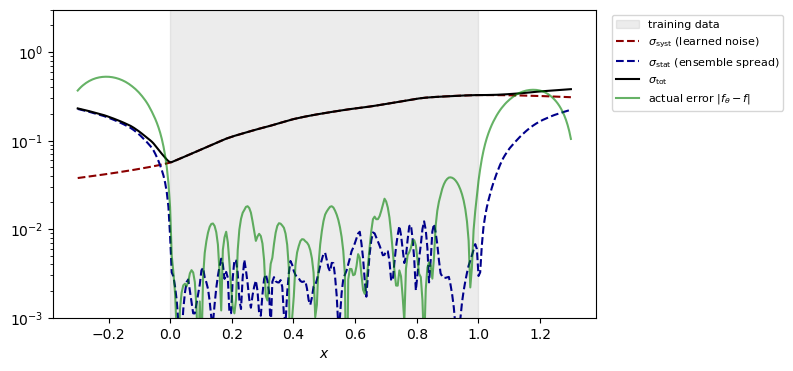

In [10]:
x = torch.linspace(-0.3, 1.3, 300)[:, None]
f_preds, sigma_preds = [], []
for k in range(5):
    torch.manual_seed(k)
    model = Regressor(n_outputs=2)
    train(model, x_train, y_train, heteroskedastic_loss, n_epochs=150)
    f_k, sigma_k = predict(model, x)
    f_preds.append(f_k)
    sigma_preds.append(sigma_k)
f_preds, sigma_preds = torch.stack(f_preds), torch.stack(sigma_preds)

f_mean = f_preds.mean(0)
sigma_stat = f_preds.std(0)                              # spread over networks
sigma_syst = (sigma_preds**2).mean(0).sqrt()             # learned noise, averaged over networks
sigma_tot = (sigma_syst**2 + sigma_stat**2).sqrt()

plt.figure(figsize=(7, 4))
plt.axvspan(0, 1, color="grey", alpha=0.15, label="training data")
plt.plot(x, sigma_syst, color="darkred", ls="--", label="$\\sigma_\\mathrm{syst}$ (learned noise)")
plt.plot(x, sigma_stat, color="darkblue", ls="--", label="$\\sigma_\\mathrm{stat}$ (ensemble spread)")
plt.plot(x, sigma_tot, color="black", label="$\\sigma_\\mathrm{tot}$")
plt.plot(x, (f_mean - f_true(x)).abs(), color="green", alpha=0.6, label="actual error $|f_\\theta - f|$")
plt.xlabel("$x$")
plt.yscale("log")
plt.ylim(1e-3, 3)
plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

**Solution notes:** inside the training data the networks agree, $\sigma_\text{stat}$ is small, and the total uncertainty is dominated by the injected noise. Outside the data the networks extrapolate differently, $\sigma_\text{stat}$ grows quickly and follows the actual error of the prediction. With more training data $\sigma_\text{stat}$ shrinks, while $\sigma_\text{syst}$ stays: exactly the separation into statistical and systematic uncertainties from the lecture.